In [15]:
import cv2, numpy as np, random, shutil
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

# ====== PENGATURAN ======
SRC_ROOT = Path("Dataset/dauncabee_split_aug")   # berisi test_murni, train_asli, train_aug
DST_ROOT = Path("Dataset/segmentasi")            # hasil segmentasi
CHK_ROOT = Path("Dataset/perlu_cek")             # gambar yang mencurigakan (disalin apa adanya)
OUT_SIZE = 224
MIN_AREA_RATIO = 0.02    # komponen < 2% luas gambar = noise
REL_AREA_RATIO = 0.25    # komponen < 25% dari daun terbesar = noise/bayangan
MAX_LEAVES = 3           # lebih dari ini -> perlu_cek
MODE = "split"           # "split" = tiap daun 1 file | "largest" = hanya daun terbesar
EXT = {".jpg", ".jpeg", ".png", ".bmp"}

In [16]:
def leaf_mask(img_bgr):
    h, w = img_bgr.shape[:2]
    blur = cv2.GaussianBlur(img_bgr, (5, 5), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)

    # Statistik pinggir gambar (perkiraan latar)
    b = max(3, int(0.03 * min(h, w)))
    def border(a):
        return np.concatenate([a[:b].reshape(-1, a.shape[2]), a[-b:].reshape(-1, a.shape[2]),
                               a[:, :b].reshape(-1, a.shape[2]), a[:, -b:].reshape(-1, a.shape[2])])
    bg_sat = np.median(border(hsv)[:, 1])

    if bg_sat < 50:
        # Latar netral (putih/abu-abu/kertas + bayangan): daun = piksel yang berwarna (saturasi tinggi)
        s = hsv[:, :, 1]
        t, _ = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        _, mask = cv2.threshold(s, max(t, 40), 255, cv2.THRESH_BINARY)
    else:
        # Latar berwarna (mis. hijau): jarak warna ke warna latar
        bg = np.median(border(lab), axis=0)
        d = np.linalg.norm(lab - bg, axis=2)
        d8 = cv2.normalize(d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        _, mask = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)

    # isi lubang di dalam daun
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    cv2.drawContours(filled, cnts, -1, 255, thickness=cv2.FILLED)
    return filled


def normalize(crop):
    h, w = crop.shape[:2]
    s = max(h, w)
    canvas = np.zeros((s, s, 3), np.uint8)
    canvas[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = crop
    return cv2.resize(canvas, (OUT_SIZE, OUT_SIZE), interpolation=cv2.INTER_AREA)


def split_leaves(img_bgr, mask):
    """return (daftar_daun, flag). flag = None kalau aman, selain itu alasan perlu dicek."""
    h, w = mask.shape
    ratio = (mask > 0).mean()
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = {i: stats[i, cv2.CC_STAT_AREA] for i in range(1, n)}
    if not areas:
        return [], "tidak_ada_daun"
    biggest = max(areas.values())
    keep = [i for i, a in areas.items() if a >= MIN_AREA_RATIO*h*w and a >= REL_AREA_RATIO*biggest]
    if not keep:
        return [], "tidak_ada_daun"

    flag = None
    if ratio > 0.85:
        flag = "mask_terlalu_luas"          # biasanya foto banyak tanaman / latar tidak terpisah
    elif len(keep) > MAX_LEAVES:
        flag = "terlalu_banyak_objek"

    keep.sort(key=lambda i: -areas[i])
    if MODE == "largest":
        keep = keep[:1]
    else:
        keep.sort(key=lambda i: stats[i, cv2.CC_STAT_LEFT])   # kiri -> kanan

    leaves = []
    for i in keep:
        x, y, bw, bh = (stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP],
                        stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT])
        m = (labels[y:y+bh, x:x+bw] == i).astype(np.uint8) * 255
        roi = img_bgr[y:y+bh, x:x+bw]
        leaves.append(normalize(cv2.bitwise_and(roi, roi, mask=m)))   # latar & daun lain -> hitam
    return leaves, flag

Total gambar: 1348


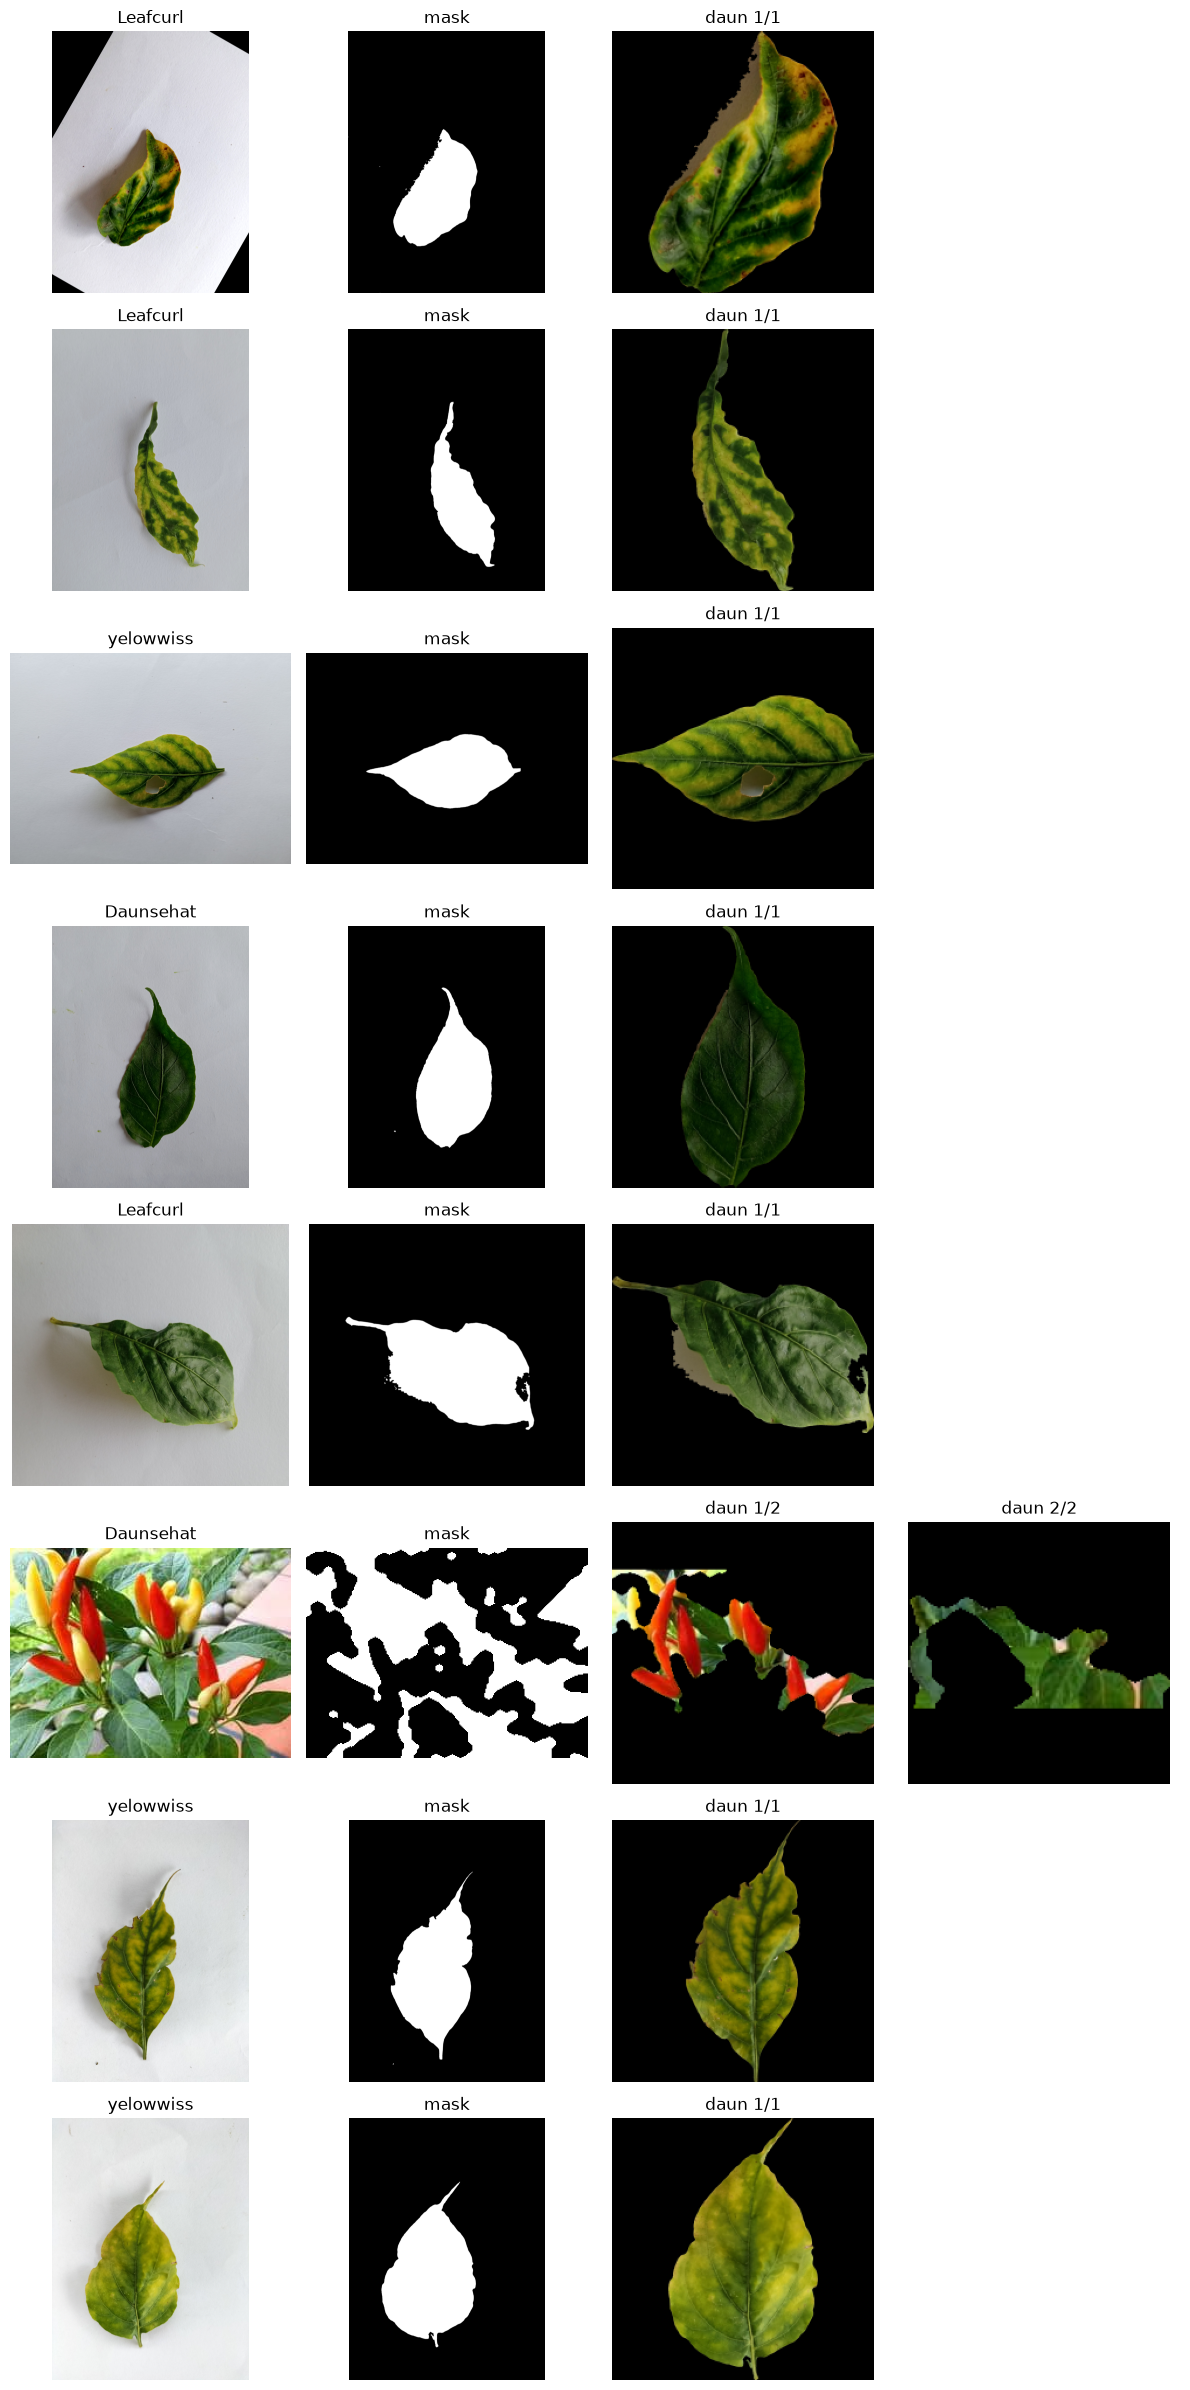

In [17]:
files = [p for p in SRC_ROOT.rglob("*") if p.suffix.lower() in EXT]
print("Total gambar:", len(files))

def preview(sample):
    fig, ax = plt.subplots(len(sample), 4, figsize=(12, 3*len(sample)))
    for r, p in enumerate(sample):
        img = cv2.imread(str(p))
        m = leaf_mask(img)
        leaves, flag = split_leaves(img, m)
        ax[r, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[r, 0].set_title(p.parent.name)
        ax[r, 1].imshow(m, cmap="gray"); ax[r, 1].set_title("PERLU CEK: "+flag if flag else "mask")
        for c in (2, 3): ax[r, c].axis("off")
        for j, lf in enumerate(leaves[:2]):
            ax[r, 2+j].imshow(cv2.cvtColor(lf, cv2.COLOR_BGR2RGB)); ax[r, 2+j].set_title(f"daun {j+1}/{len(leaves)}")
        ax[r, 0].axis("off"); ax[r, 1].axis("off")
    plt.tight_layout(); plt.show()

preview(random.sample(files, 8))

In [18]:
for sp in ["train_asli", "train_aug", "test_murni"]:
    d = SRC_ROOT / sp
    n = len([p for p in d.rglob("*") if p.suffix.lower() in EXT]) if d.exists() else None
    print(f"{sp:12s} ->", "FOLDER TIDAK ADA di " + str(d) if n is None else f"{n} gambar")

train_asli   -> 423 gambar
train_aug    -> 819 gambar
test_murni   -> 106 gambar


In [19]:
import pandas as pd
from collections import defaultdict

# bersihkan hasil lama supaya tidak tercampur
for r in (DST_ROOT, CHK_ROOT):
    if r.exists():
        shutil.rmtree(r)

files = [p for p in SRC_ROOT.rglob("*") if p.suffix.lower() in EXT]
rekap = defaultdict(Counter)                    # rekap per split
for p in files:
    rel = p.relative_to(SRC_ROOT)
    split = rel.parts[0]
    img = cv2.imread(str(p))
    rekap[split]["gambar_sumber"] += 1
    if img is None:
        rekap[split]["gagal_baca"] += 1
        continue
    leaves, flag = split_leaves(img, leaf_mask(img))
    if flag:
        rekap[split]["perlu_cek"] += 1
        (CHK_ROOT / rel.parent).mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, CHK_ROOT / rel)
        continue
    rekap[split]["file_hasil"] += len(leaves)
    out_dir = DST_ROOT / rel.parent
    out_dir.mkdir(parents=True, exist_ok=True)
    for j, lf in enumerate(leaves):
        cv2.imwrite(str(out_dir / f"{p.stem}_d{j+1}.png"), lf)

pd.DataFrame(rekap).T.fillna(0).astype(int)

,gambar_sumber,file_hasil,perlu_cek
train_aug,819,846,7
train_asli,423,436,6
test_murni,106,108,0
